In [122]:
import numpy as np
import matplotlib.pyplot as plt

In [147]:
class0 = np.random.randn(100, 2) + np.array([2,2])
class1 = np.random.randn(50, 2) + np.array([6,6])
X = np.vstack((class0, class1))
y = np.hstack((np.zeros(100), np.ones(50)))

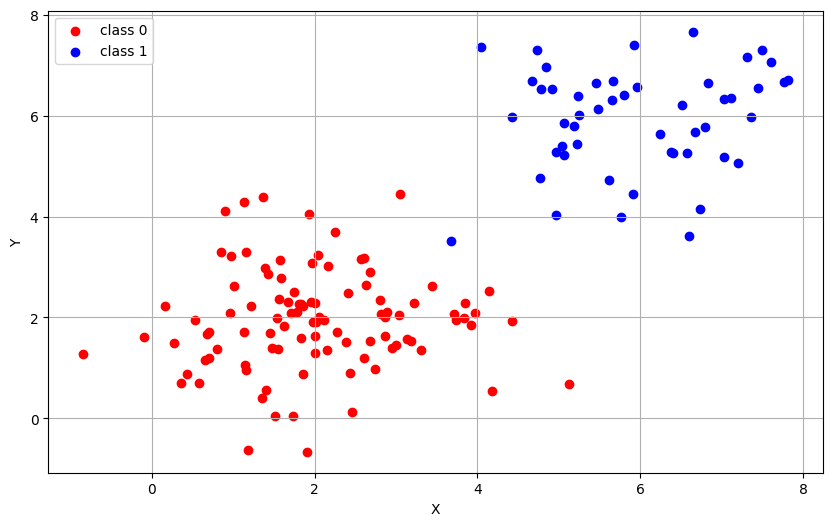

In [148]:
plt.figure(figsize=(10,6))
plt.xlabel("X")
plt.ylabel("Y")
plt.scatter(X[:100, 0], X[:100, 1], color='red', label='class 0')
plt.scatter(X[100:, 0], X[100:, 1], color='blue', label='class 1')
plt.legend()
plt.grid()
plt.show()

In [152]:
def kmedoids(X, k, iterations):
  random_indices = np.random.choice(len(X), k, replace=False)
  medoids = X[random_indices]
  distances = np.zeros((len(X), k))
  for i in range(iterations):
    for j in range(k):
      distances[:,j] = np.sqrt(
          np.sum((X - medoids[j])**2, axis=1)
      )
    clusters = np.argmin(distances, axis=1)
    new_medoids = np.zeros((k, X.shape[1]))
    for j in range(k):
      cluster_points = X[clusters==j]
      if(len(cluster_points)>0):
        total_distance = np.zeros((len(cluster_points)))
        for p in range(len(cluster_points)):
          total_distance[p] = np.sum(
              np.sqrt(
                  np.sum((cluster_points - cluster_points[p])**2, axis=1)
              )
          )
        new_medoids[j] = cluster_points[np.argmin(total_distance)]
      else:
        new_medoids[j] = medoids[j]
    if np.allclose(medoids, new_medoids):
      break
    medoids = new_medoids
  return medoids, clusters

In [153]:
k = 2
medoids, clusters = kmedoids(X, k, 500)
print(f"Medoids: \n{medoids}")
print(f"Cluster 0: {np.sum(clusters==0)}")
print(f"Cluster 1: {np.sum(clusters==1)}")

Medoids: 
[[5.65536149 6.30359357]
 [2.04991549 2.00777404]]
Cluster 0: 49
Cluster 1: 101


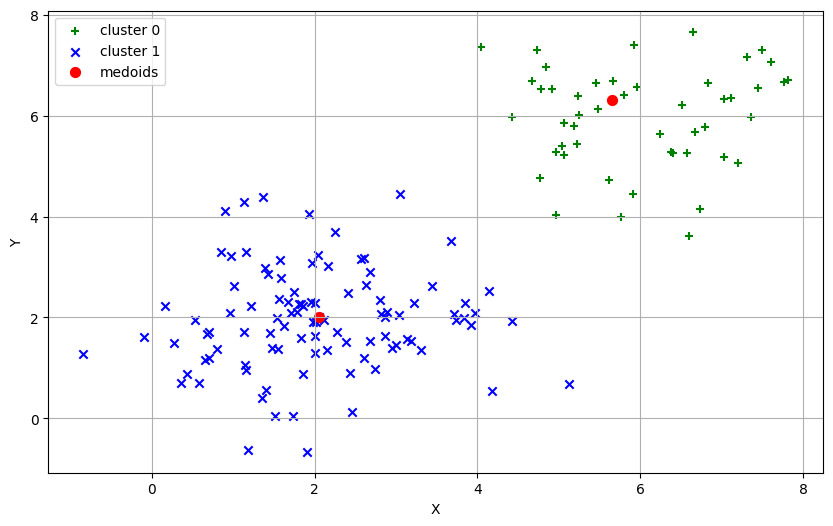

In [160]:
plt.figure(figsize=(10,6))
plt.xlabel("X")
plt.ylabel("Y")
plt.scatter(X[clusters==0, 0], X[clusters==0, 1], color='green', marker='+', label='cluster 0')
plt.scatter(X[clusters==1, 0], X[clusters==1, 1], color='blue', marker='x', label='cluster 1')
plt.scatter(medoids[:, 0], medoids[:, 1], color='red', marker='o', s=50, label='medoids')
plt.legend()
plt.grid()
plt.show()

In [155]:
direct_accuracy = np.sum(clusters==y)
reverse_accuracy = np.sum(1-clusters==y)

if reverse_accuracy > direct_accuracy:
  y_pred = 1 - clusters
else:
  y_pred = clusters

In [157]:
TP = TN = FN = FP = 0

for i in range(len(y)):
  if y[i]==1 and y_pred[i]==1:
    TP += 1
  elif y[i]==1 and y_pred[i]==0:
    FN += 1
  elif y[i]==0 and y_pred[i]==1:
    FP += 1
  elif y[i]==0 and y_pred[i]==0:
    TN += 1
confusion_matrix = np.array(([TP, FP], [FN, TN]))
print(f"Confusion Matrix: \n{confusion_matrix}")

Confusion Matrix: 
[[ 49   0]
 [  1 100]]


In [158]:
accuracy = (TP+TN)/(TP+TN+FN+FP)
precision = TP/(TP+FP) if (TP+FP)!=0 else 0
recall = TP/(TP+FN) if (TP+FN)!=0 else 0
f1_score = (2*precision*recall)/(precision+recall) if (precision+recall)!=0 else 0

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")

Accuracy: 0.9933
Precision: 1.0000
Recall: 0.9800
F1 Score: 0.9899
